# E-Commerce Sales, Customer & Profitability Analytics

**Portfolio project:** E-Commerce Sales, Customer & Profitability Analytics  



## 1. Upload the dataset




In [1]:
from google.colab import files
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

uploaded = files.upload()
uploaded_names = list(uploaded.keys())

print("Uploaded files:")
for name in uploaded_names:
    print(" -", name)

main_file = next(
    (f for f in uploaded_names if f.lower().startswith("ecommerce_sales_customer_analytics_150k") and f.lower().endswith(".csv")),
    None
)

if main_file is None:
    raise FileNotFoundError(
        "Main dataset not found. Please upload the ecommerce_sales_customer_analytics_150k CSV."
    )

df = pd.read_csv(main_file)

print(f"\nLoaded: {main_file}")
print("Rows:", len(df))
print("Columns:", len(df.columns))

Saving ecommerce_sales_customer_analytics_150k.csv to ecommerce_sales_customer_analytics_150k.csv
Saving order_items.csv to order_items.csv
Saving product_catalog.csv to product_catalog.csv
Uploaded files:
 - ecommerce_sales_customer_analytics_150k.csv
 - order_items.csv
 - product_catalog.csv

Loaded: ecommerce_sales_customer_analytics_150k.csv
Rows: 138116
Columns: 46


## 2. Understanding the dataset



In [2]:
print("Shape:", df.shape)
display(df.head())

print("\nData types:")
display(df.dtypes.to_frame("dtype"))

print("\nExact duplicate rows:", df.duplicated().sum())
print("Unique order IDs:", df["order_id"].nunique())
print("Unique customers:", df["customer_id"].nunique())

Shape: (138116, 46)


,order_id,order_date,order_time,order_status,sales_channel,customer_id,customer_name,customer_age,gender,customer_segment,customer_type,customer_city,customer_state,customer_country,region,customer_postal_code,payment_method,payment_status,currency,shipping_method,warehouse,delivery_days,estimated_delivery_days,delivery_status,return_status,return_reason,customer_rating,review_sentiment,customer_review,marketing_channel,campaign_name,coupon_code,loyalty_points_earned,loyalty_points_redeemed,quantity,gross_sales,discount_amount,tax_amount,shipping_cost,net_sales,product_cost,profit,profit_margin_percentage,customer_lifetime_value,is_repeat_customer,customer_order_count
0,ORD-301242,2023-11-06,16:37:47,Completed,Mobile App,CUST-003102,Jasmine Ryan,55,Male,Consumer,Loyal,Lake Williamberg,Texas,USA,South,86040,Digital Wallet,Paid,USD,Standard,WH-003,3.00,3.00,On Time,NaN,NaN,3.50,Positive,Satisfied with the purchase.,Direct,Default_Campaign,NaN,94,44,5,"1,350.19",477.89,61.07,12.03,945.40,588.33,345.04,36.50,"12,459.68",True,11
1,ORD-773460,2025-12-24,01:22:36,Completed,Website,CUST-003124,Scott Chase,26,Male,Premium,Loyal,Kristyport,Baden-Württemberg,Germany,South,62538,Debit Card,Pending,EUR,Economy,WH-005,10.00,10.00,On Time,NaN,NaN,3.60,Positive,Good value for money.,Direct,Default_Campaign,NaN,201,171,8,"3,144.64","1,456.06",320.83,9.00,"2,018.41","2,031.88",-22.47,-1.11,"13,032.48",True,11
2,ORD-449374,2021-07-05,14:24:21,Completed,Mobile App,CUST-012496,Marc Wheeler,69,Female,Premium,Loyal,Singletonhaven,New York,USA,East,19993,Cash on Delivery,Paid,USD,Express,WH-015,3.00,3.00,On Time,NaN,NaN,4.30,Positive,Good product. Works as expected.,YouTube,NaN,NaN,46,16,5,522.81,97.30,29.79,13.05,468.35,257.73,197.57,42.18,"6,159.44",True,6
3,ORD-567636,2023-01-21,07:20:26,Completed,Social Media,CUST-023928,Jennifer Smith,65,Male,Consumer,Loyal,Wigginsstad,North Carolina,USA,South,66329,Debit Card,Paid,USD,Express,WH-010,2.00,2.00,On Time,NaN,NaN,3.50,Positive,Satisfied with the purchase.,Email Marketing,NaN,NaN,54,10,2,544.62,53.34,34.39,20.85,546.52,277.84,247.83,45.35,"5,638.30",True,7
4,ORD-820028,2022-05-13,09:46:21,Completed,Social Media,CUST-012730,Jessica Wang,34,Female,Consumer,Loyal,New Michaelton,Gujarat,India,West,77306,Digital Wallet,Paid,INR,Standard,WH-013,6.00,5.00,Delayed,NaN,NaN,3.00,Neutral,Mixed feelings about this purchase.,Direct,NaN,NaN,278,147,6,"2,474.52",133.63,421.35,23.03,"2,785.27","1,231.88","1,530.36",54.94,"13,240.10",True,8



Data types:


,dtype
order_id,object
order_date,object
order_time,object
order_status,object
sales_channel,object
customer_id,object
customer_name,object
customer_age,int64
gender,object
customer_segment,object



Exact duplicate rows: 0
Unique order IDs: 138116
Unique customers: 24911


## 3. Missing-value analysis

Missing values are not automatically errors. For example, a missing coupon code does not necessarily mean that no coupon was used, so we will report missingness rather than blindly filling values.

In [3]:
missing = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_pct": df.isna().mean().mul(100)
}).sort_values("missing_count", ascending=False)

display(missing[missing["missing_count"] > 0])

,missing_count,missing_pct
return_reason,128654,93.15
return_status,128654,93.15
coupon_code,110502,80.01
campaign_name,83233,60.26
customer_review,24557,17.78
customer_rating,24557,17.78
estimated_delivery_days,24557,17.78
delivery_days,24557,17.78
review_sentiment,24557,17.78


## 4. Prepare dates and analysis fields

We convert the order date to a proper datetime and create reusable time fields. We also create flags for returned and loss-making orders without changing the original business values.

In [4]:
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

numeric_cols = [
    "quantity", "gross_sales", "discount_amount", "tax_amount",
    "shipping_cost", "net_sales", "product_cost", "profit",
    "profit_margin_percentage", "customer_lifetime_value",
    "loyalty_points_earned", "loyalty_points_redeemed",
    "delivery_days", "estimated_delivery_days", "customer_rating"
]

for col in numeric_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df["order_month"] = df["order_date"].dt.to_period("M").astype(str)
df["order_year"] = df["order_date"].dt.year
df["order_month_name"] = df["order_date"].dt.month_name()
df["is_returned"] = df["return_status"].eq("Returned")
df["is_cancelled"] = df["order_status"].eq("Cancelled")
df["is_loss_making"] = df["profit"] < 0

print("Date range:", df["order_date"].min().date(), "to", df["order_date"].max().date())

Date range: 2021-01-01 to 2025-12-31


## 5. Executive KPI dashboard

These are the core business KPIs.

In [5]:
total_orders = df["order_id"].nunique()
total_customers = df["customer_id"].nunique()
total_revenue = df["net_sales"].sum()
total_profit = df["profit"].sum()
profit_margin = (total_profit / total_revenue * 100) if total_revenue else np.nan
aov = total_revenue / total_orders if total_orders else np.nan
return_rate = df["is_returned"].sum() / total_orders * 100 if total_orders else np.nan
cancellation_rate = df["is_cancelled"].sum() / total_orders * 100 if total_orders else np.nan
loss_orders = df["is_loss_making"].sum()
loss_order_pct = loss_orders / total_orders * 100 if total_orders else np.nan

kpis = pd.DataFrame({
    "KPI": [
        "Total Orders", "Total Customers", "Net Sales",
        "Total Profit", "Profit Margin", "Average Order Value",
        "Return Rate", "Cancellation Rate",
        "Loss-Making Orders", "Loss-Making Order %"
    ],
    "Value": [
        total_orders, total_customers, total_revenue,
        total_profit, profit_margin, aov,
        return_rate, cancellation_rate,
        loss_orders, loss_order_pct
    ]
})

display(kpis)

,KPI,Value
0,Total Orders,"138,116.00"
1,Total Customers,"24,911.00"
2,Net Sales,"177,134,263.74"
3,Total Profit,"76,146,395.76"
4,Profit Margin,42.99
5,Average Order Value,"1,282.50"
6,Return Rate,6.85
7,Cancellation Rate,6.08
8,Loss-Making Orders,"1,296.00"
9,Loss-Making Order %,0.94


## 6. Data-quality checks

These checks are intended to identify issues worth investigating. Negative profit is treated as a business outcome rather than automatically being deleted.

In [6]:
quality_checks = pd.DataFrame({
    "Check": [
        "Missing order IDs",
        "Missing customer IDs",
        "Missing order dates",
        "Negative quantity",
        "Negative net sales",
        "Negative product cost",
        "Negative delivery days",
        "Negative estimated delivery days",
        "Negative profit / loss-making orders"
    ],
    "Count": [
        df["order_id"].isna().sum(),
        df["customer_id"].isna().sum(),
        df["order_date"].isna().sum(),
        (df["quantity"] < 0).sum(),
        (df["net_sales"] < 0).sum(),
        (df["product_cost"] < 0).sum(),
        (df["delivery_days"] < 0).sum(),
        (df["estimated_delivery_days"] < 0).sum(),
        (df["profit"] < 0).sum()
    ]
})

display(quality_checks)

,Check,Count
0,Missing order IDs,0
1,Missing customer IDs,0
2,Missing order dates,0
3,Negative quantity,0
4,Negative net sales,0
5,Negative product cost,0
6,Negative delivery days,0
7,Negative estimated delivery days,0
8,Negative profit / loss-making orders,1296


## 7. Monthly sales and profit trend

A monthly trend helps identify seasonality, growth/decline periods, and unusually strong or weak months.

In [7]:
monthly = (
    df.groupby("order_month", as_index=False)
      .agg(
          revenue=("net_sales", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique")
      )
      .sort_values("order_month")
)

display(monthly.head(12))

,order_month,revenue,profit,orders
0,2021-01,"2,374,415.22","1,129,764.43",1906
1,2021-02,"1,905,413.15","900,452.55",1565
2,2021-03,"2,753,256.18","1,298,951.77",2166
3,2021-04,"2,469,384.78","1,178,381.90",1943
4,2021-05,"2,546,555.37","1,219,361.44",2096
5,2021-06,"2,710,208.64","1,292,627.89",2203
6,2021-07,"2,894,416.72","1,143,965.61",2036
7,2021-08,"3,220,659.48","1,526,095.90",2474
8,2021-09,"2,720,931.59","1,224,683.15",2134
9,2021-10,"2,991,778.76","1,413,407.38",2324


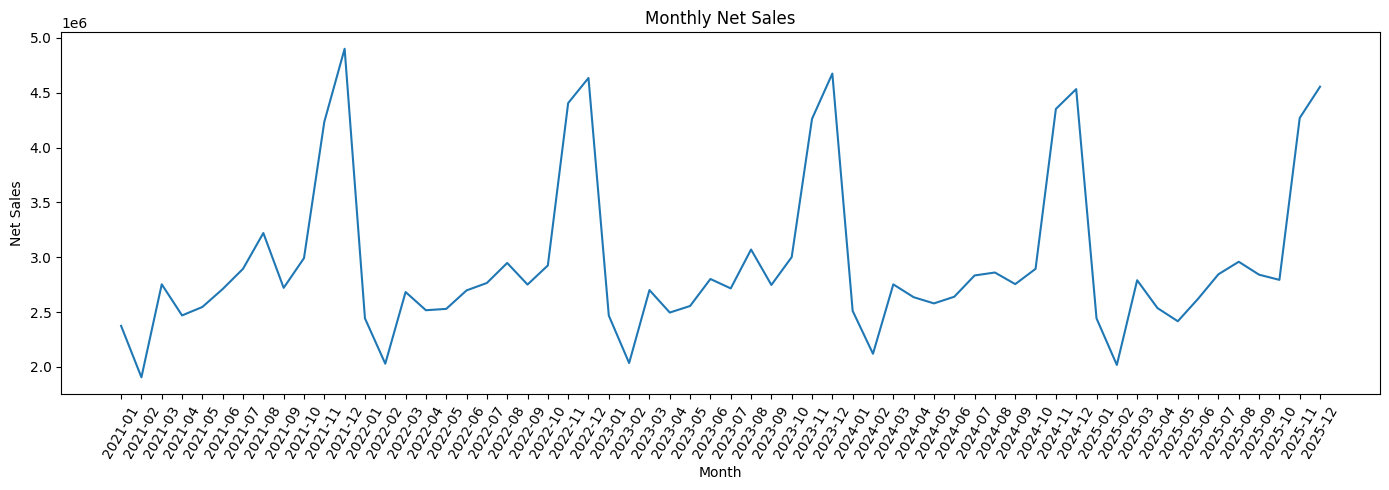

In [8]:
plt.figure(figsize=(14, 5))
plt.plot(monthly["order_month"], monthly["revenue"])
plt.title("Monthly Net Sales")
plt.xlabel("Month")
plt.ylabel("Net Sales")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

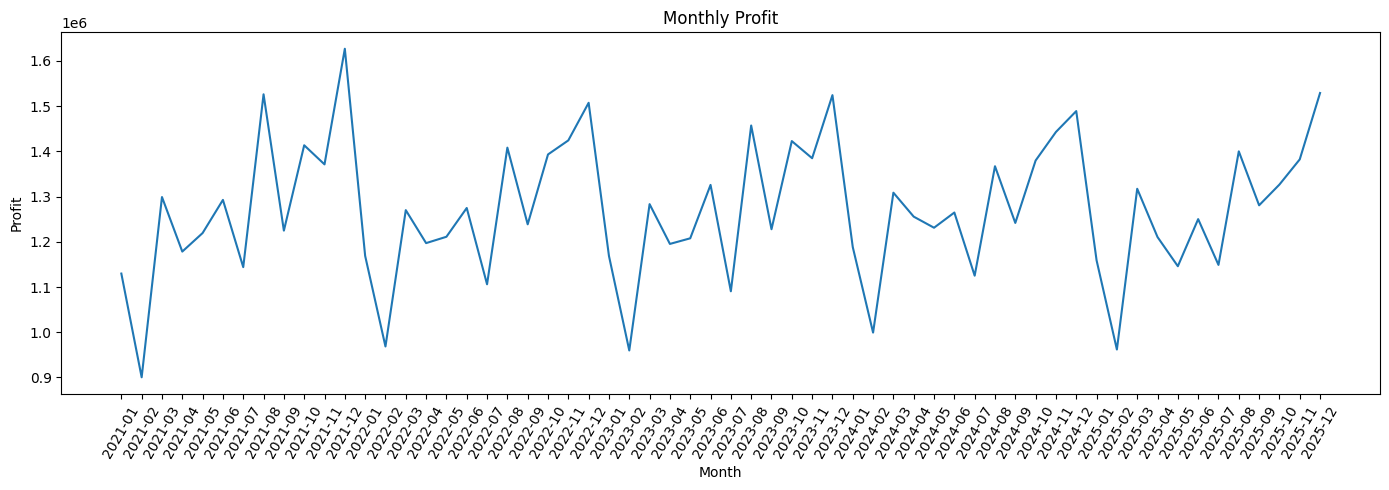

In [9]:
plt.figure(figsize=(14, 5))
plt.plot(monthly["order_month"], monthly["profit"])
plt.title("Monthly Profit")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()

## 8. Sales channel and customer segment analysis

This section compares revenue and profitability across the main commercial segments.

In [10]:
channel_performance = (
    df.groupby("sales_channel", as_index=False)
      .agg(
          revenue=("net_sales", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique")
      )
)
channel_performance["profit_margin_pct"] = (
    channel_performance["profit"] / channel_performance["revenue"] * 100
)

segment_performance = (
    df.groupby("customer_segment", as_index=False)
      .agg(
          revenue=("net_sales", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique"),
          customers=("customer_id", "nunique")
      )
)
segment_performance["profit_margin_pct"] = (
    segment_performance["profit"] / segment_performance["revenue"] * 100
)

display(channel_performance.sort_values("revenue", ascending=False))
display(segment_performance.sort_values("revenue", ascending=False))

,sales_channel,revenue,profit,orders,profit_margin_pct
1,Mobile App,"70,834,782.53","30,451,112.22",55318,42.99
3,Website,"61,854,736.08","26,639,693.01",48237,43.07
0,Marketplace,"26,696,190.22","11,414,227.16",20698,42.76
2,Social Media,"17,748,554.91","7,641,363.37",13863,43.05


,customer_segment,revenue,profit,orders,customers,profit_margin_pct
1,Consumer,"97,201,007.90","42,819,790.02",75636,13585,44.05
2,Premium,"44,269,794.13","18,177,727.78",34746,6275,41.06
3,VIP,"17,903,164.81","7,366,352.68",13957,2536,41.15
0,Business,"17,760,296.90","7,782,525.28",13777,2515,43.82


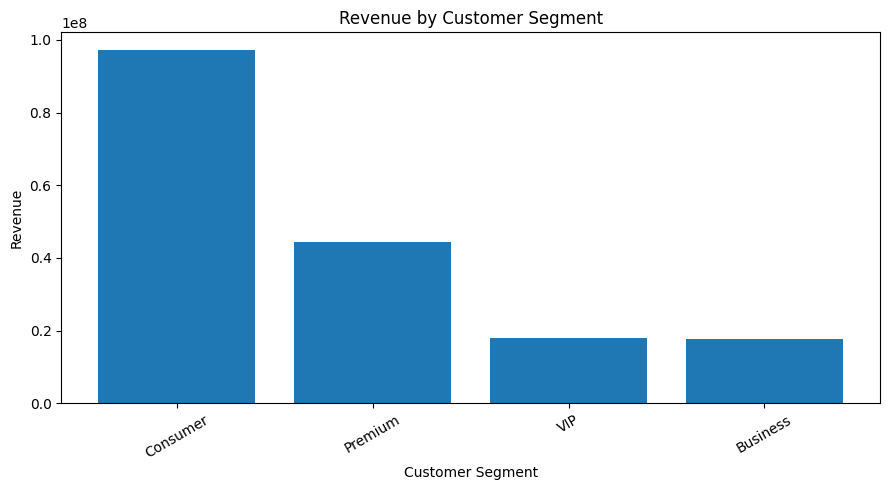

In [11]:
plt.figure(figsize=(9, 5))
plot_data = segment_performance.sort_values("revenue", ascending=False)
plt.bar(plot_data["customer_segment"], plot_data["revenue"])
plt.title("Revenue by Customer Segment")
plt.xlabel("Customer Segment")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 9. Customer analytics

We build a customer-level summary to identify high-value customers and understand customer purchasing behavior.

In [12]:
customer_summary = (
    df.groupby(["customer_id", "customer_name"], as_index=False)
      .agg(
          revenue=("net_sales", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique"),
          quantity=("quantity", "sum"),
          avg_order_value=("net_sales", "mean"),
          avg_rating=("customer_rating", "mean")
      )
)

customer_summary["profit_margin_pct"] = (
    customer_summary["profit"] / customer_summary["revenue"].replace(0, np.nan) * 100
)

print("Top 10 customers by revenue:")
display(customer_summary.sort_values("revenue", ascending=False).head(10))

print("Top 10 customers by profit:")
display(customer_summary.sort_values("profit", ascending=False).head(10))

Top 10 customers by revenue:


,customer_id,customer_name,revenue,profit,orders,quantity,avg_order_value,avg_rating,profit_margin_pct
12818,CUST-012869,Dylan Clark,"30,268.44","11,818.95",15,96,"2,017.90",3.83,39.05
2958,CUST-002969,Tracy Mendez,"30,061.58","11,703.80",16,99,"1,878.85",3.94,38.93
17184,CUST-017251,Jesus Ross,"29,375.34","10,563.05",15,110,"1,958.36",3.54,35.96
800,CUST-000802,Rodney Avila,"28,503.23","12,782.04",12,90,"2,375.27",3.70,44.84
12559,CUST-012608,James Long,"28,172.12","13,993.62",13,87,"2,167.09",3.86,49.67
17760,CUST-017828,Joyce Cooper,"28,092.99","12,397.89",14,92,"2,006.64",3.63,44.13
6828,CUST-006857,Hailey Cox,"26,835.08","9,357.22",10,79,"2,683.51",3.60,34.87
17456,CUST-017523,Ryan Stewart,"26,776.65","12,663.43",9,88,"2,975.18",3.71,47.29
8783,CUST-008822,Patrick Hunter,"25,803.66","11,059.20",10,63,"2,580.37",3.88,42.86
1739,CUST-001747,Kristie Lucas,"25,737.14","11,624.00",15,92,"1,715.81",3.77,45.16


Top 10 customers by profit:


,customer_id,customer_name,revenue,profit,orders,quantity,avg_order_value,avg_rating,profit_margin_pct
12559,CUST-012608,James Long,"28,172.12","13,993.62",13,87,"2,167.09",3.86,49.67
800,CUST-000802,Rodney Avila,"28,503.23","12,782.04",12,90,"2,375.27",3.70,44.84
17456,CUST-017523,Ryan Stewart,"26,776.65","12,663.43",9,88,"2,975.18",3.71,47.29
17760,CUST-017828,Joyce Cooper,"28,092.99","12,397.89",14,92,"2,006.64",3.63,44.13
12975,CUST-013026,Steven Caldwell,"24,478.99","12,101.33",12,63,"2,039.92",3.61,49.44
2372,CUST-002381,Shawn Murphy,"25,690.76","12,086.76",10,59,"2,569.08",3.80,47.05
7857,CUST-007893,Zachary Soto,"24,072.74","12,025.13",10,68,"2,407.27",3.68,49.95
15115,CUST-015177,Jason Rodriguez,"22,238.41","11,932.92",7,54,"3,176.92",3.90,53.66
11753,CUST-011800,Jorge Barry,"25,158.01","11,931.01",12,86,"2,096.50",3.87,47.42
12818,CUST-012869,Dylan Clark,"30,268.44","11,818.95",15,96,"2,017.90",3.83,39.05


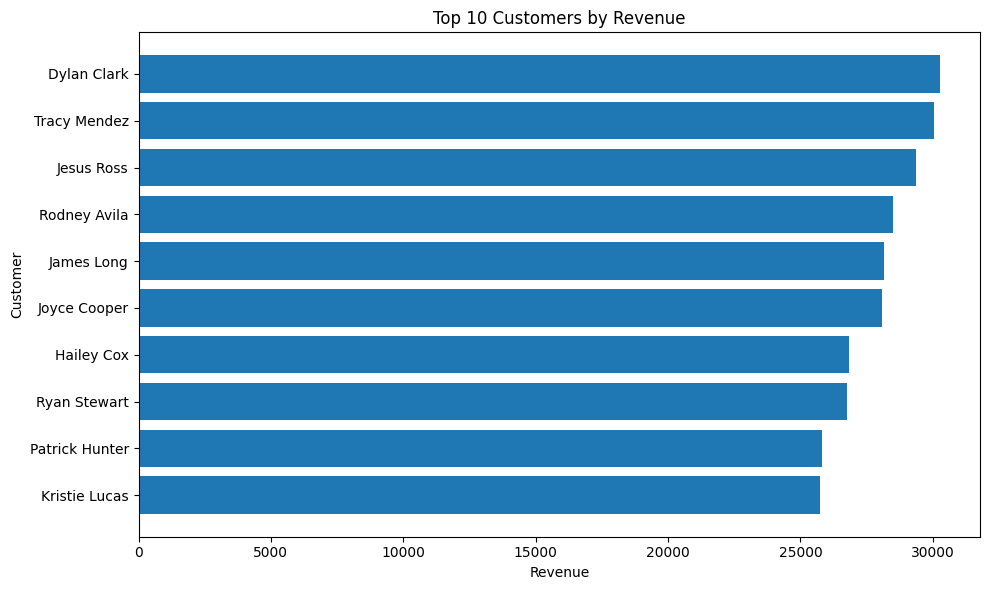

In [13]:
top_customers = customer_summary.sort_values("revenue", ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_customers["customer_name"].astype(str), top_customers["revenue"])
plt.title("Top 10 Customers by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Customer")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 10. Repeat-customer analysis

Repeat customers are useful for understanding retention and customer value.

In [14]:
repeat_summary = (
    df.groupby("customer_id")
      .agg(
          orders=("order_id", "nunique"),
          revenue=("net_sales", "sum"),
          profit=("profit", "sum")
      )
      .reset_index()
)

repeat_summary["customer_type"] = np.where(
    repeat_summary["orders"] > 1, "Repeat", "One-time"
)

repeat_counts = repeat_summary["customer_type"].value_counts().rename_axis("customer_type").reset_index(name="customers")
repeat_counts["pct"] = repeat_counts["customers"] / repeat_counts["customers"].sum() * 100

display(repeat_counts)

,customer_type,customers,pct
0,Repeat,24387,97.90
1,One-time,524,2.10


## 11. Product and category analysis

If `order_items` and `product_catalog` were uploaded, we can perform true product-level analysis. This is more reliable than trying to infer a product from the order-level dataset.

In [15]:
def find_uploaded(prefix):
    return next(
        (f for f in uploaded_names if f.lower().startswith(prefix.lower()) and f.lower().endswith(".csv")),
        None
    )

order_items_file = find_uploaded("order_items")
product_file = find_uploaded("product_catalog")

if order_items_file and product_file:
    order_items = pd.read_csv(order_items_file)
    products = pd.read_csv(product_file)

    oi_products = order_items.merge(
        products,
        on="product_id",
        how="left",
        suffixes=("", "_catalog")
    )

    category_performance = (
        oi_products.groupby("product_category", as_index=False)
        .agg(
            revenue=("net_sales", "sum"),
            profit=("profit", "sum"),
            units=("quantity", "sum"),
            products=("product_id", "nunique")
        )
    )
    category_performance["profit_margin_pct"] = (
        category_performance["profit"] /
        category_performance["revenue"].replace(0, np.nan) * 100
    )

    product_performance = (
        oi_products.groupby(["product_id", "product_name"], as_index=False)
        .agg(
            revenue=("net_sales", "sum"),
            profit=("profit", "sum"),
            units=("quantity", "sum")
        )
    )
    product_performance["profit_margin_pct"] = (
        product_performance["profit"] /
        product_performance["revenue"].replace(0, np.nan) * 100
    )

    print("Category performance:")
    display(category_performance.sort_values("revenue", ascending=False))

    print("Top 10 products by revenue:")
    display(product_performance.sort_values("revenue", ascending=False).head(10))

    print("Top 10 products by profit:")
    display(product_performance.sort_values("profit", ascending=False).head(10))
else:
    print("Supporting product files were not uploaded.")
    print("Upload order_items and product_catalog to run product/category analysis.")

Category performance:


,product_category,revenue,profit,units,products,profit_margin_pct
4,Electronics,"41,148,162.90","14,103,982.74",55784,78,34.28
10,Jewelry,"25,561,333.78","10,391,635.32",48859,69,40.65
9,Home Appliances,"24,842,478.64","10,288,878.45",56281,78,41.42
0,Automotive,"16,449,898.28","6,477,194.28",58046,81,39.38
13,Sports & Outdoors,"15,726,848.17","7,230,037.31",64752,91,45.97
8,Home & Kitchen,"10,971,629.82","5,203,824.25",49682,70,47.43
1,Baby & Kids,"9,690,605.60","4,818,148.07",53945,75,49.72
7,Health & Wellness,"9,228,068.04","4,263,304.41",62054,86,46.20
11,Office Supplies,"8,884,212.85","4,585,377.04",57631,80,51.61
5,Fashion,"7,434,589.51","3,669,631.60",48774,68,49.36


Top 10 products by revenue:


,product_id,product_name,revenue,profit,units,profit_margin_pct
64,PROD-000065,Xiaomi Self-enabling exuding productivity Gami...,"956,726.44","315,731.45",743,33.00
61,PROD-000062,OnePlus Adaptive uniform success Gaming Consoles,"946,819.10","376,805.41",767,39.80
73,PROD-000074,Asus Configurable upward-trending matrix TVs,"943,941.34","300,483.49",778,31.83
23,PROD-000024,Asus Re-engineered content-based strategy Tablets,"942,549.52","286,463.16",673,30.39
50,PROD-000051,HP Versatile actuating budgetary management Sm...,"909,388.15","364,187.95",717,40.05
76,PROD-000077,OnePlus Switchable methodical neural-net TVs,"900,378.69","287,872.13",716,31.97
42,PROD-000043,OnePlus Streamlined modular infrastructure Sma...,"885,456.49","242,450.76",754,27.38
11,PROD-000012,LG Reverse-engineered even-keeled workforce Sm...,"883,013.59","216,683.84",668,24.54
62,PROD-000063,Xiaomi Fundamental motivating task-force Gamin...,"857,409.58","285,324.29",738,33.28
55,PROD-000056,HP Function-based neutral access Cameras,"853,769.80","335,125.63",711,39.25


Top 10 products by profit:


,product_id,product_name,revenue,profit,units,profit_margin_pct
61,PROD-000062,OnePlus Adaptive uniform success Gaming Consoles,"946,819.10","376,805.41",767,39.80
995,PROD-000996,Messika Networked disintermediate knowledge us...,"684,252.98","366,529.63",782,53.57
50,PROD-000051,HP Versatile actuating budgetary management Sm...,"909,388.15","364,187.95",717,40.05
3,PROD-000004,Sony Customer-focused systematic support Smart...,"789,273.24","344,305.93",782,43.62
55,PROD-000056,HP Function-based neutral access Cameras,"853,769.80","335,125.63",711,39.25
1002,PROD-001003,Tous Diverse impactful software Chains,"589,385.21","331,429.03",694,56.23
951,PROD-000952,Mikimoto Monitored zero administration website...,"618,159.49","326,125.53",728,52.76
4,PROD-000005,OnePlus Quality-focused background parallelism...,"781,814.68","318,948.00",662,40.80
64,PROD-000065,Xiaomi Self-enabling exuding productivity Gami...,"956,726.44","315,731.45",743,33.00
73,PROD-000074,Asus Configurable upward-trending matrix TVs,"943,941.34","300,483.49",778,31.83


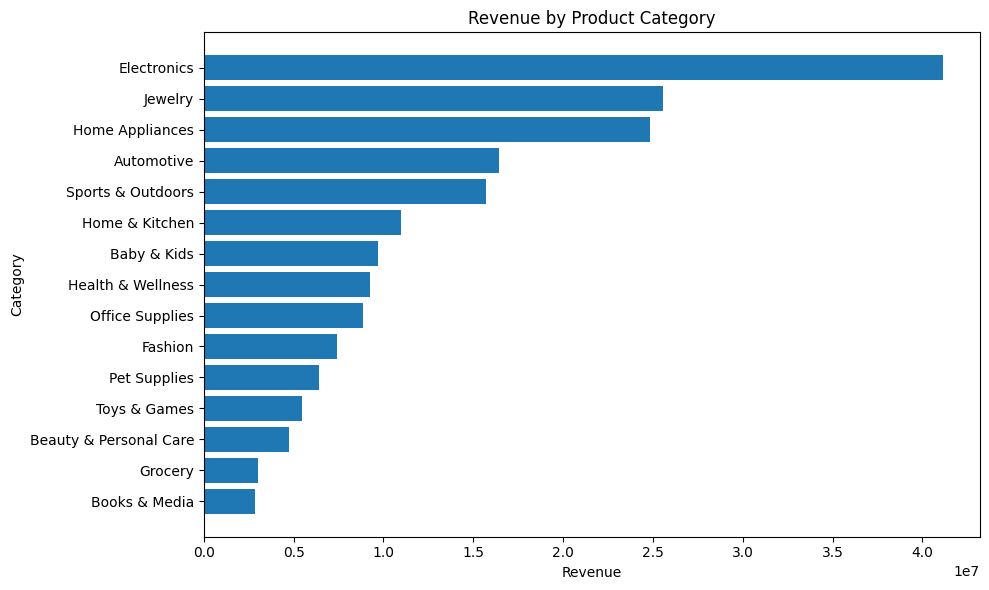

In [16]:
if "category_performance" in globals():
    top_categories = category_performance.sort_values("revenue", ascending=False)

    plt.figure(figsize=(10, 6))
    plt.barh(top_categories["product_category"], top_categories["revenue"])
    plt.title("Revenue by Product Category")
    plt.xlabel("Revenue")
    plt.ylabel("Category")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

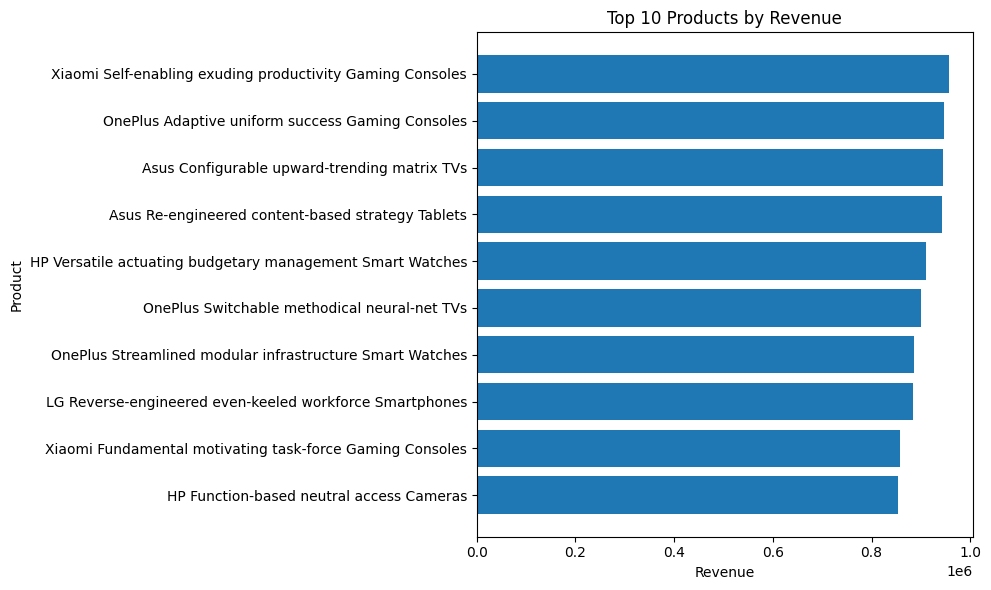

In [17]:
if "product_performance" in globals():
    top_products = product_performance.sort_values("revenue", ascending=False).head(10)

    plt.figure(figsize=(10, 6))
    plt.barh(top_products["product_name"].astype(str), top_products["revenue"])
    plt.title("Top 10 Products by Revenue")
    plt.xlabel("Revenue")
    plt.ylabel("Product")
    plt.gca().invert_yaxis()
    plt.tight_layout()
    plt.show()

## 12. Marketing performance

Compare marketing channels and campaigns using revenue, profit, and margin. Missing campaign/coupon values are retained as missing rather than being assumed to mean "no campaign".

In [18]:
marketing = (
    df.groupby("marketing_channel", dropna=False, as_index=False)
      .agg(
          revenue=("net_sales", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique")
      )
)
marketing["profit_margin_pct"] = (
    marketing["profit"] / marketing["revenue"].replace(0, np.nan) * 100
)

campaign = (
    df.groupby("campaign_name", dropna=False, as_index=False)
      .agg(
          revenue=("net_sales", "sum"),
          profit=("profit", "sum"),
          orders=("order_id", "nunique")
      )
)
campaign["profit_margin_pct"] = (
    campaign["profit"] / campaign["revenue"].replace(0, np.nan) * 100
)

display(marketing.sort_values("revenue", ascending=False))
display(campaign.sort_values("revenue", ascending=False).head(15))

,marketing_channel,revenue,profit,orders,profit_margin_pct
6,Organic Search,"35,658,209.46","15,313,174.30",27742,42.94
4,Google Ads,"26,540,586.44","11,356,389.55",20633,42.79
1,Direct,"26,117,885.52","11,280,316.74",20515,43.19
3,Facebook Ads,"21,372,470.11","9,189,184.91",16651,43.00
5,Instagram,"17,676,446.46","7,585,410.75",13801,42.91
2,Email Marketing,"14,420,446.43","6,177,791.79",11218,42.84
7,Referral,"14,342,124.81","6,186,481.45",11191,43.14
0,Affiliate,"8,827,899.78","3,805,557.93",6848,43.11
8,TikTok,"6,980,204.06","3,011,928.49",5437,43.15
9,YouTube,"5,197,990.67","2,240,159.85",4080,43.10


,campaign_name,revenue,profit,orders,profit_margin_pct
17,NaN,"107,049,758.00","46,029,058.45",83233,43.00
2,Default_Campaign,"29,369,870.74","12,661,955.99",22989,43.11
8,Google_Search_Q1,"3,528,425.03","1,507,557.08",2748,42.73
9,Google_Shopping,"3,508,726.99","1,504,036.16",2746,42.87
7,Google_Display,"3,467,009.87","1,502,560.11",2731,43.34
3,FB_Dynamic,"2,882,313.90","1,213,705.75",2233,42.11
6,Friend_Invite,"2,865,524.05","1,232,408.22",2232,43.01
4,FB_Prospecting,"2,835,289.51","1,228,137.77",2161,43.32
15,Referral_Program,"2,819,962.94","1,214,858.40",2198,43.08
5,FB_Retargeting,"2,782,783.18","1,191,086.42",2270,42.80


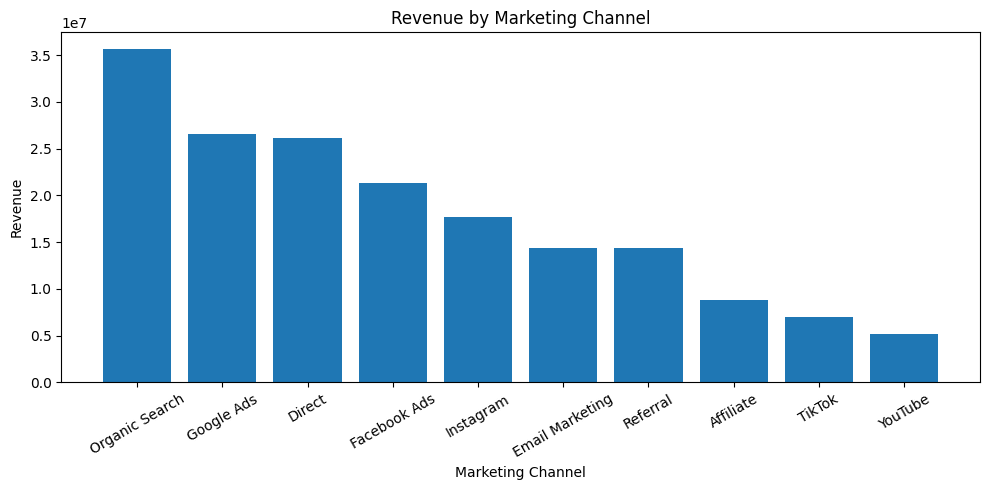

In [19]:
marketing_plot = marketing.dropna(subset=["marketing_channel"]).sort_values("revenue", ascending=False)

plt.figure(figsize=(10, 5))
plt.bar(marketing_plot["marketing_channel"].astype(str), marketing_plot["revenue"])
plt.title("Revenue by Marketing Channel")
plt.xlabel("Marketing Channel")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 13. Returns analysis

Returned orders are analyzed by return reason. We do not fill missing return values because missingness can represent orders that were never returned.

,return_reason,returned_orders,revenue,profit
7,Wrong Product,1237,"1,713,592.86","903,519.92"
4,Other,1208,"1,593,155.92","842,842.57"
0,Changed Mind,1204,"1,672,745.83","883,018.81"
6,Size Issue,1182,"1,660,543.67","870,998.72"
2,Defective Product,1174,"1,630,606.75","862,464.49"
3,Late Delivery,1172,"1,649,827.09","861,778.42"
5,Product Not as Expected,1147,"1,594,147.31","835,705.71"
1,Damaged Product,1138,"1,658,055.36","865,268.76"


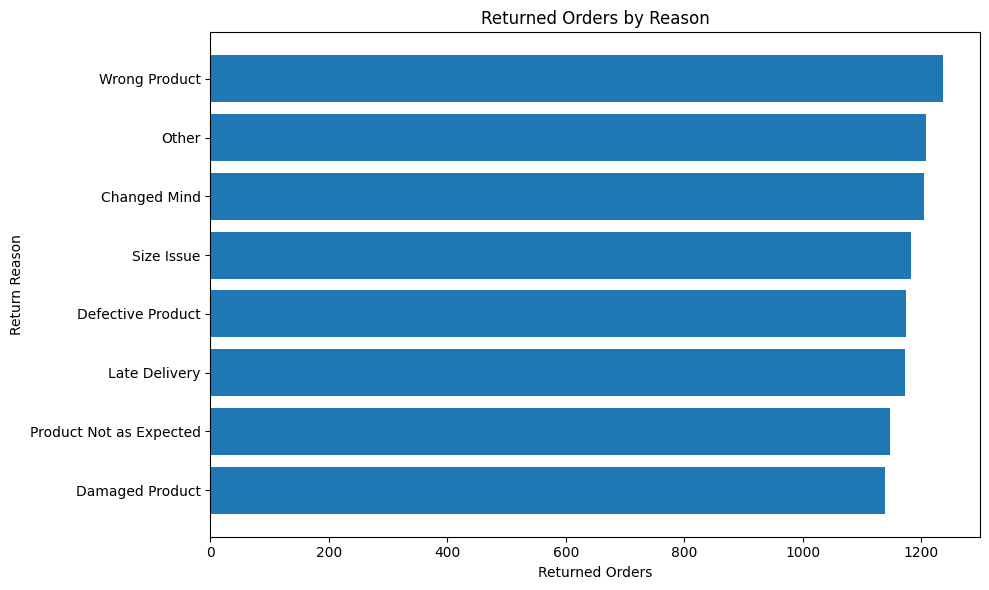

In [20]:
returned = df[df["is_returned"]].copy()

return_reasons = (
    returned.groupby("return_reason", dropna=False)
    .agg(
        returned_orders=("order_id", "nunique"),
        revenue=("net_sales", "sum"),
        profit=("profit", "sum")
    )
    .reset_index()
    .sort_values("returned_orders", ascending=False)
)

display(return_reasons)

plt.figure(figsize=(10, 6))
plt.barh(return_reasons["return_reason"].astype(str), return_reasons["returned_orders"])
plt.title("Returned Orders by Reason")
plt.xlabel("Returned Orders")
plt.ylabel("Return Reason")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

## 14. Operations and delivery performance

This section looks at delivery status, shipping methods, warehouses, and delivery times.

In [21]:
delivery_status = (
    df.groupby("delivery_status", dropna=False, as_index=False)
      .agg(
          orders=("order_id", "nunique"),
          revenue=("net_sales", "sum"),
          profit=("profit", "sum")
      )
      .sort_values("orders", ascending=False)
)

shipping = (
    df.groupby("shipping_method", dropna=False, as_index=False)
      .agg(
          orders=("order_id", "nunique"),
          avg_delivery_days=("delivery_days", "mean"),
          avg_estimated_days=("estimated_delivery_days", "mean"),
          revenue=("net_sales", "sum")
      )
)

warehouse = (
    df.groupby("warehouse", dropna=False, as_index=False)
      .agg(
          orders=("order_id", "nunique"),
          avg_delivery_days=("delivery_days", "mean"),
          revenue=("net_sales", "sum"),
          profit=("profit", "sum")
      )
)

display(delivery_status)
display(shipping)
display(warehouse)

,delivery_status,orders,revenue,profit
3,On Time,86916,"110,295,898.28","45,687,906.29"
0,Cancelled,24557,"32,938,425.24","16,387,926.73"
1,Delayed,16886,"21,455,059.73","8,876,468.15"
2,Early,9757,"12,444,880.49","5,194,094.59"


,shipping_method,orders,avg_delivery_days,avg_estimated_days,revenue
0,Economy,27824,7.74,7.50,"35,637,406.57"
1,Express,34373,2.26,2.00,"44,003,664.18"
2,Same Day,13913,0.82,0.49,"18,023,854.99"
3,Standard,62006,5.25,5.00,"79,469,338.00"


,warehouse,orders,avg_delivery_days,revenue,profit
0,WH-001,7199,4.50,"9,350,793.79","4,016,157.32"
1,WH-002,7154,4.55,"9,230,744.09","3,960,717.16"
2,WH-003,7305,4.60,"9,414,514.26","4,005,174.48"
3,WH-004,7384,4.59,"9,451,750.74","4,056,388.77"
4,WH-005,7236,4.56,"9,277,334.10","3,991,383.79"
5,WH-006,7345,4.57,"9,296,649.65","4,004,580.18"
6,WH-007,7294,4.53,"9,476,087.59","4,044,508.97"
7,WH-008,7206,4.57,"9,356,381.75","4,020,243.59"
8,WH-009,7239,4.56,"9,173,059.19","3,955,318.28"
9,WH-010,7139,4.55,"9,110,080.04","3,927,227.20"


## 15. Loss-making orders

Loss-making transactions can reveal discounting problems, high costs, returns, or other profitability issues. We report them rather than deleting them.

In [22]:
loss_summary = pd.DataFrame({
    "Metric": [
        "Loss-making orders",
        "Total orders",
        "Loss-making order %",
        "Revenue from loss-making orders",
        "Profit from loss-making orders"
    ],
    "Value": [
        loss_orders,
        total_orders,
        loss_order_pct,
        df.loc[df["is_loss_making"], "net_sales"].sum(),
        df.loc[df["is_loss_making"], "profit"].sum()
    ]
})

display(loss_summary)

loss_by_channel = (
    df.groupby("sales_channel", as_index=False)
      .agg(
          loss_orders=("is_loss_making", "sum"),
          total_orders=("order_id", "nunique"),
          loss_profit=("profit", lambda x: x[x < 0].sum())
      )
)

loss_by_channel["loss_order_pct"] = (
    loss_by_channel["loss_orders"] /
    loss_by_channel["total_orders"].replace(0, np.nan) * 100
)

display(loss_by_channel.sort_values("loss_order_pct", ascending=False))

,Metric,Value
0,Loss-making orders,"1,296.00"
1,Total orders,"138,116.00"
2,Loss-making order %,0.94
3,Revenue from loss-making orders,"1,783,736.45"
4,Profit from loss-making orders,"-201,225.34"


,sales_channel,loss_orders,total_orders,loss_profit,loss_order_pct
2,Social Media,145,13863,"-21,949.68",1.05
1,Mobile App,527,55318,"-80,410.62",0.95
3,Website,447,48237,"-66,476.32",0.93
0,Marketplace,177,20698,"-32,388.72",0.86


## 16. Best and weakest periods

This creates concise business-ready findings from the calculated results.

In [23]:
best_revenue_month = monthly.loc[monthly["revenue"].idxmax()]
best_profit_month = monthly.loc[monthly["profit"].idxmax()]
worst_profit_month = monthly.loc[monthly["profit"].idxmin()]

print("Best month by revenue:")
print(best_revenue_month.to_dict())

print("\nBest month by profit:")
print(best_profit_month.to_dict())

print("\nWeakest month by profit:")
print(worst_profit_month.to_dict())

if "category_performance" in globals():
    top_category = category_performance.sort_values("revenue", ascending=False).iloc[0]
    print("\nTop product category by revenue:")
    print(top_category.to_dict())

if "product_performance" in globals():
    top_product = product_performance.sort_values("revenue", ascending=False).iloc[0]
    print("\nTop product by revenue:")
    print(top_product.to_dict())

top_customer = customer_summary.sort_values("revenue", ascending=False).iloc[0]
print("\nTop customer by revenue:")
print(top_customer.to_dict())

top_marketing = marketing.sort_values("revenue", ascending=False).iloc[0]
print("\nTop marketing channel by revenue:")
print(top_marketing.to_dict())

Best month by revenue:
{'order_month': '2021-12', 'revenue': 4900970.07, 'profit': 1626795.03, 'orders': 3568}

Best month by profit:
{'order_month': '2021-12', 'revenue': 4900970.07, 'profit': 1626795.03, 'orders': 3568}

Weakest month by profit:
{'order_month': '2021-02', 'revenue': 1905413.15, 'profit': 900452.55, 'orders': 1565}

Top product category by revenue:
{'product_category': 'Electronics', 'revenue': 41148162.9, 'profit': 14103982.74, 'units': 55784, 'products': 78, 'profit_margin_pct': 34.276093380586865}

Top product by revenue:
{'product_id': 'PROD-000065', 'product_name': 'Xiaomi Self-enabling exuding productivity Gaming Consoles', 'revenue': 956726.44, 'profit': 315731.45, 'units': 743, 'profit_margin_pct': 33.00122551227915}

Top customer by revenue:
{'customer_id': 'CUST-012869', 'customer_name': 'Dylan Clark', 'revenue': 30268.44, 'profit': 11818.949999999999, 'orders': 15, 'quantity': 96, 'avg_order_value': 2017.896, 'avg_rating': 3.8333333333333335, 'profit_margin

## 17.Business insights


In [24]:
print("BUSINESS INSIGHTS")
print("=" * 70)

print(f"1. The dataset contains {total_orders:,} unique orders from {total_customers:,} customers.")
print(f"2. Total net sales are {total_revenue:,.2f}, with total profit of {total_profit:,.2f}.")
print(f"3. Overall profit margin is {profit_margin:.2f}% and average order value is {aov:,.2f}.")
print(f"4. Return rate is {return_rate:.2f}% and cancellation rate is {cancellation_rate:.2f}%.")
print(f"5. {loss_order_pct:.2f}% of orders are loss-making, highlighting an area for profitability investigation.")
print(f"6. The strongest revenue month is {best_revenue_month['order_month']}.")
print(f"7. The strongest profit month is {best_profit_month['order_month']}.")

if "category_performance" in globals():
    print(f"8. The top revenue category is {top_category['product_category']}.")

if "product_performance" in globals():
    print(f"9. The top revenue product is {top_product['product_name']}.")

print(f"10. The highest-revenue customer is {top_customer['customer_name']}.")
print(f"11. The highest-revenue marketing channel is {top_marketing['marketing_channel']}.")

BUSINESS INSIGHTS
1. The dataset contains 138,116 unique orders from 24,911 customers.
2. Total net sales are 177,134,263.74, with total profit of 76,146,395.76.
3. Overall profit margin is 42.99% and average order value is 1,282.50.
4. Return rate is 6.85% and cancellation rate is 6.08%.
5. 0.94% of orders are loss-making, highlighting an area for profitability investigation.
6. The strongest revenue month is 2021-12.
7. The strongest profit month is 2021-12.
8. The top revenue category is Electronics.
9. The top revenue product is Xiaomi Self-enabling exuding productivity Gaming Consoles.
10. The highest-revenue customer is Dylan Clark.
11. The highest-revenue marketing channel is Organic Search.


## 18. Final project summary

### What this project demonstrates

- Data loading and preparation with Pandas
- Data-quality validation
- KPI calculation
- Time-series sales analysis
- Customer analytics
- Product/category profitability
- Marketing performance analysis
- Return and operations analysis
- Loss-making transaction investigation
- Business insight generation
- Power BI-ready summary tables

